# 12 · Paper figures
CPU runtime, under a minute. Redraws the chapter's figures from the CSVs that notebooks 08-11 saved, formatted for
print: no titles (they go in the captions), ~12 cm wide, 9 pt text, readable in greyscale (markers, hatching, line
styles instead of colour alone). Each figure is saved as vector PDF and as 600-dpi PNG in `v2/paper_figures/`.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.metrics import r2_score, confusion_matrix, brier_score_loss
from sklearn.calibration import calibration_curve

OUT = "/content/drive/MyDrive/szakdolgozat/v2"
RES = f"{OUT}/results"
FIG = f"{OUT}/paper_figures"
os.makedirs(FIG, exist_ok=True)

W = 4.7                       # inches ≈ 12 cm, Springer text width
DARK, MID, LIGHT = "#1f3b57", "#6f8fa8", "#c9d6e0"
plt.rcParams.update({"font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9, "legend.fontsize": 8,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e3e3e3",
                     "grid.linewidth": 0.6, "savefig.bbox": "tight", "savefig.pad_inches": 0.02})

def save(fig, name):
    fig.savefig(f"{FIG}/{name}.pdf")
    fig.savefig(f"{FIG}/{name}.png", dpi=600)
    plt.show()

mos = pd.read_csv(f"{OUT}/mos_test_preds.csv")
hit = pd.read_csv(f"{OUT}/hit_test_preds.csv")

## Fig. 1 · MOS distribution per partition

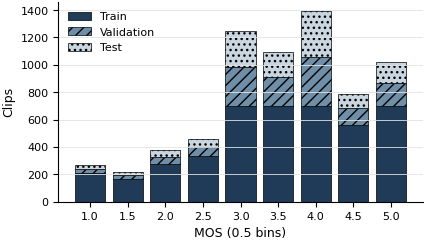

In [3]:
bins = pd.read_csv(f"{RES}/mos_bins_by_split_final.csv", index_col=0)[["train", "val", "test"]]
fig, ax = plt.subplots(figsize=(W, 2.6))
bottom = np.zeros(len(bins))
for col, label, color, hatch in [("train", "Train", DARK, None), ("val", "Validation", MID, "///"),
                                 ("test", "Test", LIGHT, "...")]:
    ax.bar(bins.index.astype(str), bins[col], bottom=bottom, color=color, hatch=hatch,
           edgecolor="black", linewidth=0.5, label=label)
    bottom += bins[col].values
ax.set_xlabel("MOS (0.5 bins)"); ax.set_ylabel("Clips"); ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
save(fig, "fig1_mos_distribution")

## Fig. 7 · Predicted vs true MOS

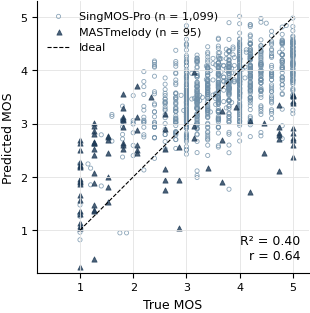

In [4]:
fig, ax = plt.subplots(figsize=(W * 0.75, W * 0.75))
for src, label, marker, color, size in [("singmos", "SingMOS-Pro", "o", MID, 9), ("mast", "MASTmelody", "^", DARK, 14)]:
    g = mos[mos.source == src]
    ax.scatter(g.mos, g.pred, s=size, marker=marker, facecolors="none" if src == "singmos" else color,
               edgecolors=color, linewidths=0.6, alpha=0.8, label=f"{label} (n = {len(g):,})")
ax.plot([1, 5], [1, 5], "k--", lw=0.8, label="Ideal")
lo, hi = min(0.2, mos.pred.min() - 0.1), max(5.3, mos.pred.max() + 0.1)
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
ax.set_xlabel("True MOS"); ax.set_ylabel("Predicted MOS")
ax.text(0.97, 0.04, f"R² = {r2_score(mos.mos, mos.pred):.2f}\nr = {pearsonr(mos.mos, mos.pred)[0]:.2f}",
        transform=ax.transAxes, ha="right", va="bottom")
ax.legend(frameon=False, loc="upper left")
save(fig, "fig7_mos_scatter")

## Fig. 8 · Training curve of the final model
Log scale, so the first epoch does not flatten the rest. The marked epoch uses the same rule as training
(improvement of at least 0.001 in validation MSE).

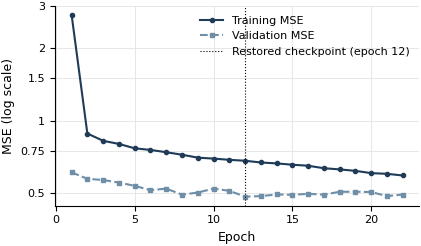

best epoch 12 | stopped after 22


In [5]:
hist = pd.read_csv(f"{RES}/mos_loss_history_seed0.csv")
best, best_epoch = np.inf, 0
for e, v in zip(hist.epoch, hist.val_mse):
    if v < best - 1e-3:
        best, best_epoch = v, e
fig, ax = plt.subplots(figsize=(W, 2.6))
ax.plot(hist.epoch, hist.train_mse, "-", color=DARK, marker="o", ms=3, label="Training MSE")
ax.plot(hist.epoch, hist.val_mse, "--", color=MID, marker="s", ms=3, label="Validation MSE")
ax.axvline(best_epoch, color="black", lw=0.8, ls=":", label=f"Restored checkpoint (epoch {best_epoch})")
ax.set_yscale("log"); ax.set_yticks([0.5, 0.75, 1, 1.5, 2, 3]); ax.set_yticklabels(["0.5", "0.75", "1", "1.5", "2", "3"])
ax.minorticks_off()
ax.set_xlabel("Epoch"); ax.set_ylabel("MSE (log scale)"); ax.legend(frameon=False)
save(fig, "fig8_mos_loss")
print("best epoch", best_epoch, "| stopped after", len(hist))

## Fig. 9 · Hit classifier: confusion matrix and reliability diagram
Bars under the reliability curve show how many test tracks fall in each probability bin.

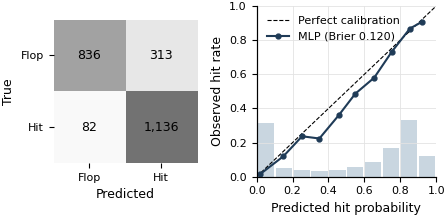

   mean_predicted  observed    gap
0           0.019     0.015 -0.004
1           0.149     0.120 -0.029
2           0.253     0.237 -0.016
3           0.349     0.224 -0.125
4           0.456     0.359 -0.097
5           0.549     0.486 -0.063
6           0.655     0.580 -0.075
7           0.754     0.733 -0.020
8           0.854     0.868  0.015
9           0.919     0.906 -0.013


In [6]:
y, p = hit.target.values, hit.prob.values
cm = confusion_matrix(y, (p >= 0.5).astype(int))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(W, 2.4), gridspec_kw={"width_ratios": [1, 1.25]})
a1.imshow(cm, cmap="Greys", vmin=0, vmax=cm.max() * 1.6)
for (i, j), v in np.ndenumerate(cm):
    a1.text(j, i, f"{v:,}", ha="center", va="center", color="black")
a1.set_xticks([0, 1], ["Flop", "Hit"]); a1.set_yticks([0, 1], ["Flop", "Hit"])
a1.set_xlabel("Predicted"); a1.set_ylabel("True"); a1.grid(False)
for s in a1.spines.values():
    s.set_visible(False)

frac, mean_pred = calibration_curve(y, p, n_bins=10)
counts, edges = np.histogram(p, bins=10, range=(0, 1))
a2b = a2.twinx()
a2b.bar(edges[:-1] + 0.05, counts, width=0.09, color=LIGHT, edgecolor="none", zorder=0)
a2b.set_ylim(0, counts.max() * 3); a2b.set_yticks([]); a2b.spines["right"].set_visible(False)
a2.set_zorder(a2b.get_zorder() + 1); a2.patch.set_visible(False)
a2.plot([0, 1], [0, 1], "k--", lw=0.8, label="Perfect calibration")
a2.plot(mean_pred, frac, "-o", color=DARK, ms=3.5, label=f"MLP (Brier {brier_score_loss(y, p):.3f})")
a2.set_xlim(0, 1); a2.set_ylim(0, 1)
a2.set_xlabel("Predicted hit probability"); a2.set_ylabel("Observed hit rate"); a2.legend(frameon=False, loc="upper left")
fig.tight_layout()
save(fig, "fig9_hit_confusion_calibration")
print(pd.DataFrame({"mean_predicted": mean_pred.round(3), "observed": frac.round(3),
                    "gap": (frac - mean_pred).round(3)}))

## Fig. 10 · Weight sensitivity of the combined ranking (batch 100)

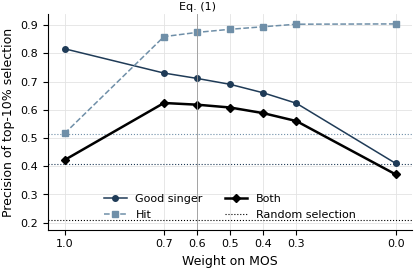

In [7]:
sens = pd.read_csv(f"{RES}/table_ranking_weight_sensitivity.csv")
sens = sens[sens.batch_size == 100].set_index("w_mos").sort_index(ascending=False)
mean = lambda col: sens[col].str.split("±").str[0].astype(float)
rand = {"prec_good_singer": (mos.mos >= 4.0).mean(), "prec_hit": hit.target.mean()}
rand["prec_both"] = rand["prec_good_singer"] * rand["prec_hit"]

fig, ax = plt.subplots(figsize=(W, 2.8))
for col, label, ls, marker in [("prec_good_singer", "Good singer", "-", "o"), ("prec_hit", "Hit", "--", "s"),
                               ("prec_both", "Both", "-", "D")]:
    color = "black" if col == "prec_both" else (DARK if col == "prec_good_singer" else MID)
    ax.plot(sens.index, mean(col), ls=ls, marker=marker, ms=4, color=color, label=label,
            lw=1.8 if col == "prec_both" else 1.1)
    ax.axhline(rand[col], color=color, ls=":", lw=0.8)
ax.plot([], [], "k:", lw=0.8, label="Random selection")
ax.axvline(0.6, color="#999999", lw=0.6)
ax.text(0.6, 1.01, "Eq. (1)", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8)
ax.invert_xaxis(); ax.set_xticks(sens.index)
ax.set_xlabel("Weight on MOS"); ax.set_ylabel("Precision of top-10% selection")
ax.legend(frameon=False, ncol=2, loc="lower center")
save(fig, "fig10_ranking_weight_sensitivity")

## Fig. 11 · Transposition (final model)

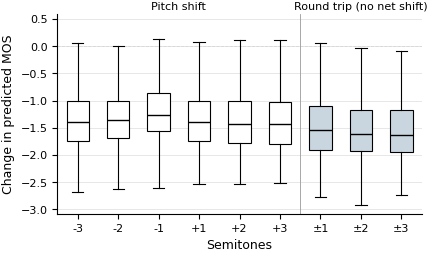

saved to /content/drive/MyDrive/szakdolgozat/v2/paper_figures : ['fig10_ranking_weight_sensitivity.pdf', 'fig10_ranking_weight_sensitivity.png', 'fig11_mos_transposition.pdf', 'fig11_mos_transposition.png', 'fig1_mos_distribution.pdf', 'fig1_mos_distribution.png', 'fig7_mos_scatter.pdf', 'fig7_mos_scatter.png', 'fig8_mos_loss.pdf', 'fig8_mos_loss.png', 'fig9_hit_confusion_calibration.pdf', 'fig9_hit_confusion_calibration.png']


In [8]:
tr = pd.read_csv(f"{OUT}/mos_transpose_preds.csv")
base = tr[tr.kind == "none"].set_index("wav").pred_shift
tr = tr[tr.kind != "none"].assign(delta=lambda d: d.pred_shift - base.loc[d.wav].values)
keys = [("shift", s) for s in [-3, -2, -1, 1, 2, 3]] + [("roundtrip", s) for s in [1, 2, 3]]
labels = [f"{s:+d}" for _, s in keys[:6]] + [f"±{s}" for _, s in keys[6:]]

fig, ax = plt.subplots(figsize=(W, 2.6))
ax.axhline(0, color="#999999", lw=0.6, ls="--", zorder=0)
bp = ax.boxplot([tr.delta[(tr.kind == k) & (tr["shift"] == s)] for k, s in keys], showfliers=False, widths=0.55,
                patch_artist=True, medianprops={"color": "black"}, boxprops={"linewidth": 0.8},
                whiskerprops={"linewidth": 0.8}, capprops={"linewidth": 0.8})
for i, box in enumerate(bp["boxes"]):
    box.set_facecolor("white" if i < 6 else LIGHT)       # shaded = round trip
ax.set_xticks(range(1, len(keys) + 1), labels)
ax.axvline(6.5, color="#999999", lw=0.6)
ax.set_ylim(top=0.6)
for x, text in [(3.5, "Pitch shift"), (8, "Round trip (no net shift)")]:
    ax.text(x, 1.01, text, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8)
ax.set_xlabel("Semitones"); ax.set_ylabel("Change in predicted MOS"); ax.grid(axis="x", visible=False)
save(fig, "fig11_mos_transposition")
print("saved to", FIG, ":", sorted(os.listdir(FIG)))